##**Loading the Taxis Dataset**

In [1]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:

df = sns.load_dataset("taxis")


In [3]:

df.head()


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [4]:

print("Number of rows and columns:", df.shape)


Number of rows and columns: (6433, 14)


In [5]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

In [6]:

df.describe(include="all")


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000,6433,6389,6407,6388,6407,6388
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,194,203,4,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yellow,credit card,Midtown Center,Upper East Side North,Manhattan,Manhattan
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5451,4577,230,245,5268,5206
mean,2019-03-16 08:31:28.514223616,2019-03-16 08:45:49.491217408,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794,NaN,NaN,NaN,NaN,NaN,NaN
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000,NaN,NaN,NaN,NaN,NaN,NaN
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000,NaN,NaN,NaN,NaN,NaN,NaN
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000,NaN,NaN,NaN,NaN,NaN,NaN
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000,NaN,NaN,NaN,NaN,NaN,NaN
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000,NaN,NaN,NaN,NaN,NaN,NaN


##**Handling Missing Values**

In [7]:

print(df.isnull().sum())


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [8]:

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])


payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [9]:

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage[missing_percentage > 0].round(2))


payment            0.68
pickup_zone        0.40
dropoff_zone       0.70
pickup_borough     0.40
dropoff_borough    0.70
dtype: float64


In [10]:

# Make a copy so the original dataset remains unchanged
df = df.copy()

# Fill missing values in numerical columns with the median
numerical_cols = df.select_dtypes(include="number").columns

for col in numerical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill missing values in categorical columns with the mode
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for col in categorical_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])

print("Missing values after imputation:")
print(df.isnull().sum())


Missing values after imputation:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [11]:

# Convert pickup to datetime format
df["pickup"] = pd.to_datetime(df["pickup"], errors="coerce")

# Remove rows where critical values are still missing
critical_cols = [
    "pickup", "fare", "distance", "tip", "total",
    "payment", "pickup_borough", "pickup_zone"
]

df = df.dropna(subset=critical_cols).copy()

print("Dataset shape after cleaning:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum())


Dataset shape after cleaning: (6433, 14)

Remaining missing values:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [12]:

print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Missing values in critical columns:")
print(df[critical_cols].isnull().sum())


Total rows: 6433
Total columns: 14
Missing values in critical columns:
pickup            0
fare              0
distance          0
tip               0
total             0
payment           0
pickup_borough    0
pickup_zone       0
dtype: int64


##**Visualizations using Matplotlib and Pandas**

###**Line Chart**

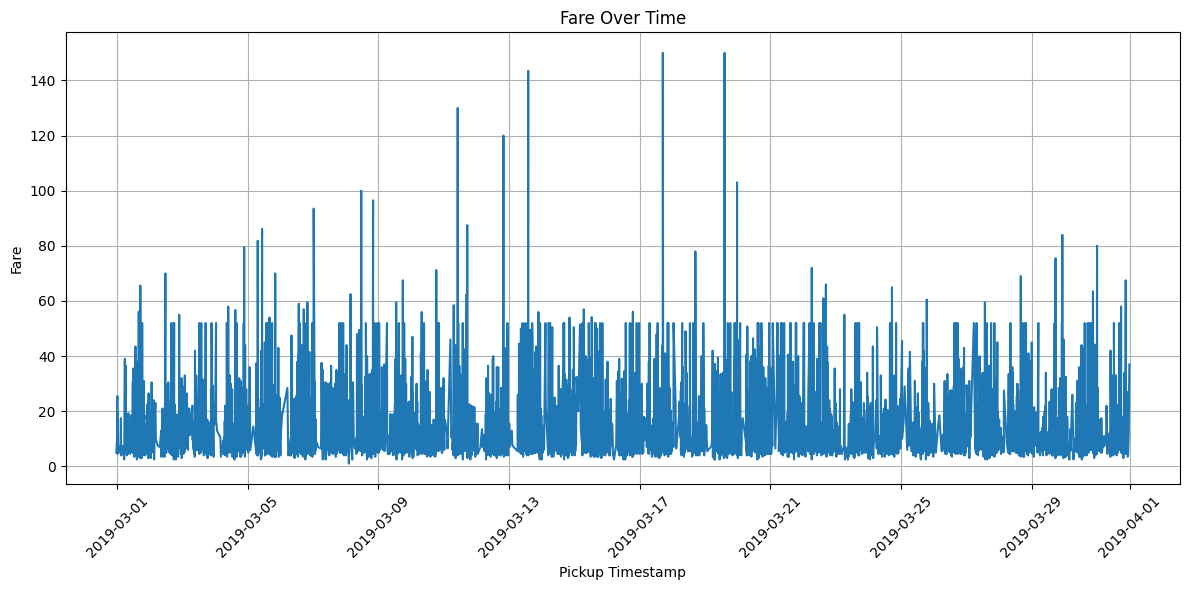

In [13]:

# Sort data by pickup time
line_df = df.sort_values("pickup")

# Create line chart
plt.figure(figsize=(12, 6))
plt.plot(line_df["pickup"], line_df["fare"])

plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


###**Bar Chart**

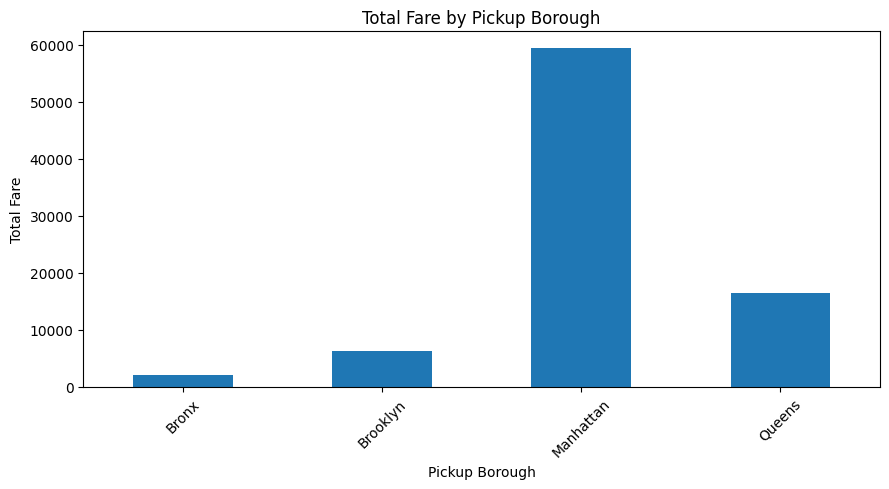

In [14]:

borough_fare = df.groupby("pickup_borough")["fare"].sum()

borough_fare.plot(
    kind="bar",
    figsize=(9, 5),
    title="Total Fare by Pickup Borough"
)

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


###**Pie Chart**

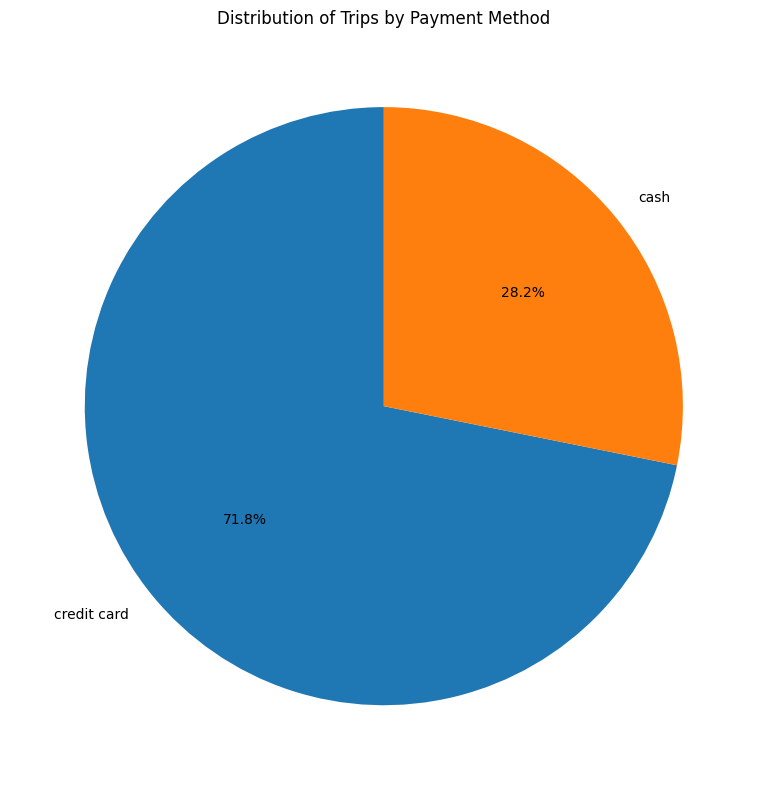

In [15]:

payment_counts = df["payment"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.tight_layout()
plt.show()


###**Histogram**

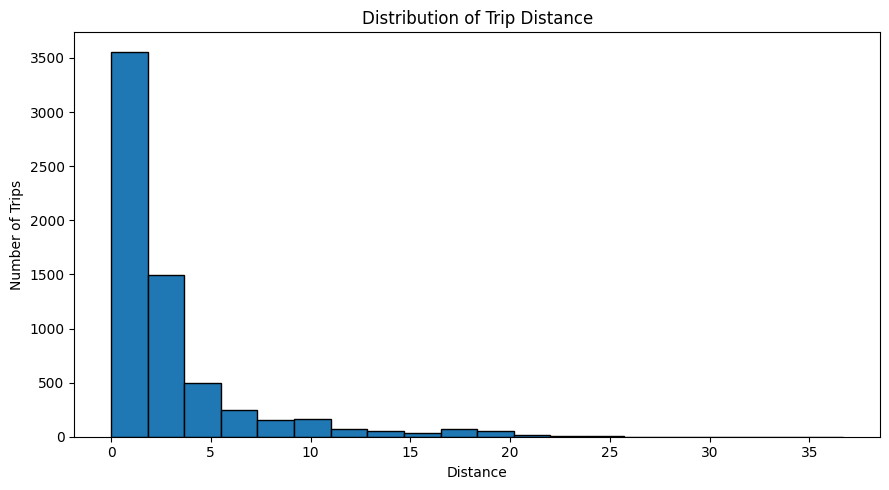

In [16]:

plt.figure(figsize=(9, 5))

plt.hist(df["distance"], bins=20, edgecolor="black")

plt.title("Distribution of Trip Distance")
plt.xlabel("Distance")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()


###**Box Plot**

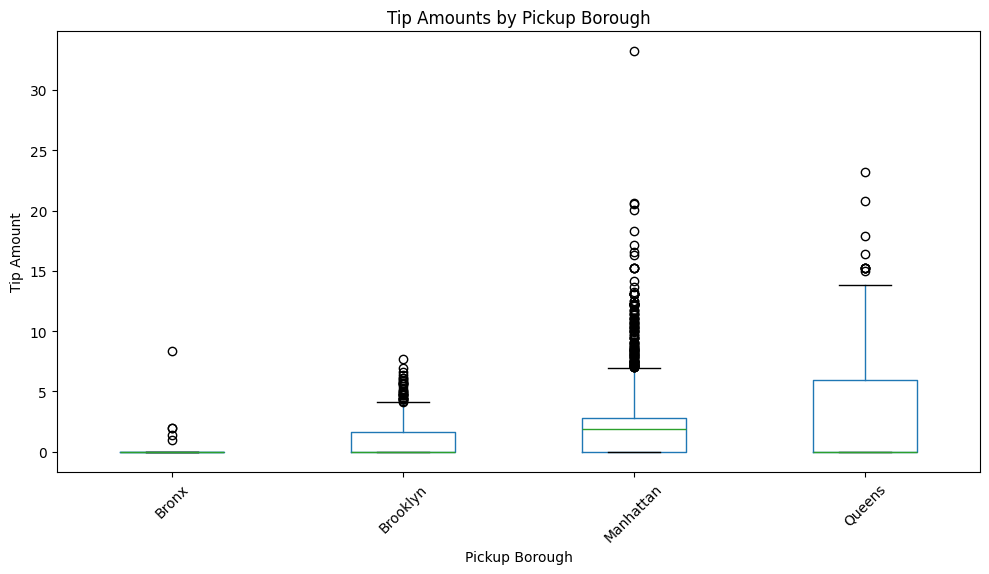

In [17]:

df.boxplot(
    column="tip",
    by="pickup_borough",
    figsize=(10, 6),
    grid=False
)

plt.title("Tip Amounts by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


##**Visualizations using Seaborn**

###**Count Plot**

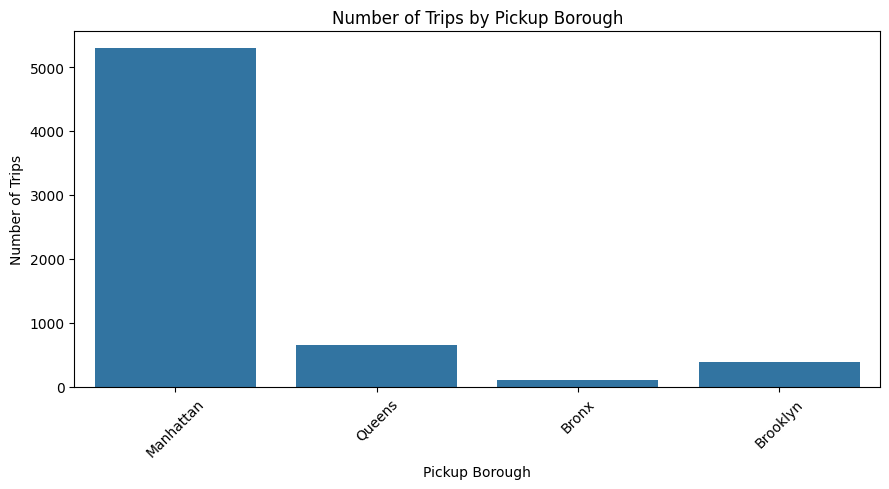

In [18]:

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="pickup_borough")

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


###**Scatter Plot**

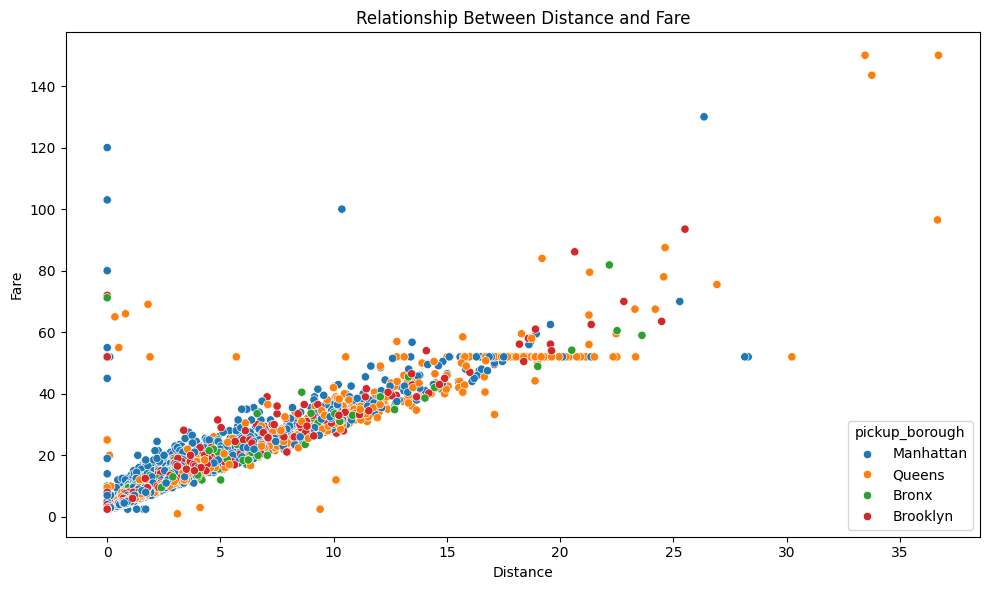

In [19]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)

plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()


###**Heat Map**

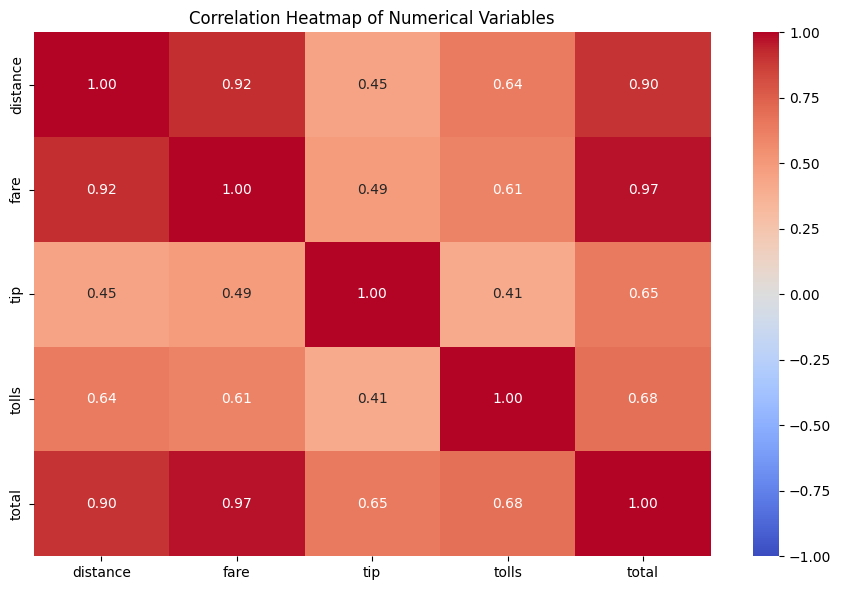

In [20]:

numerical_data = df[["distance", "fare", "tip", "tolls", "total"]]

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


###**Pair Plot**

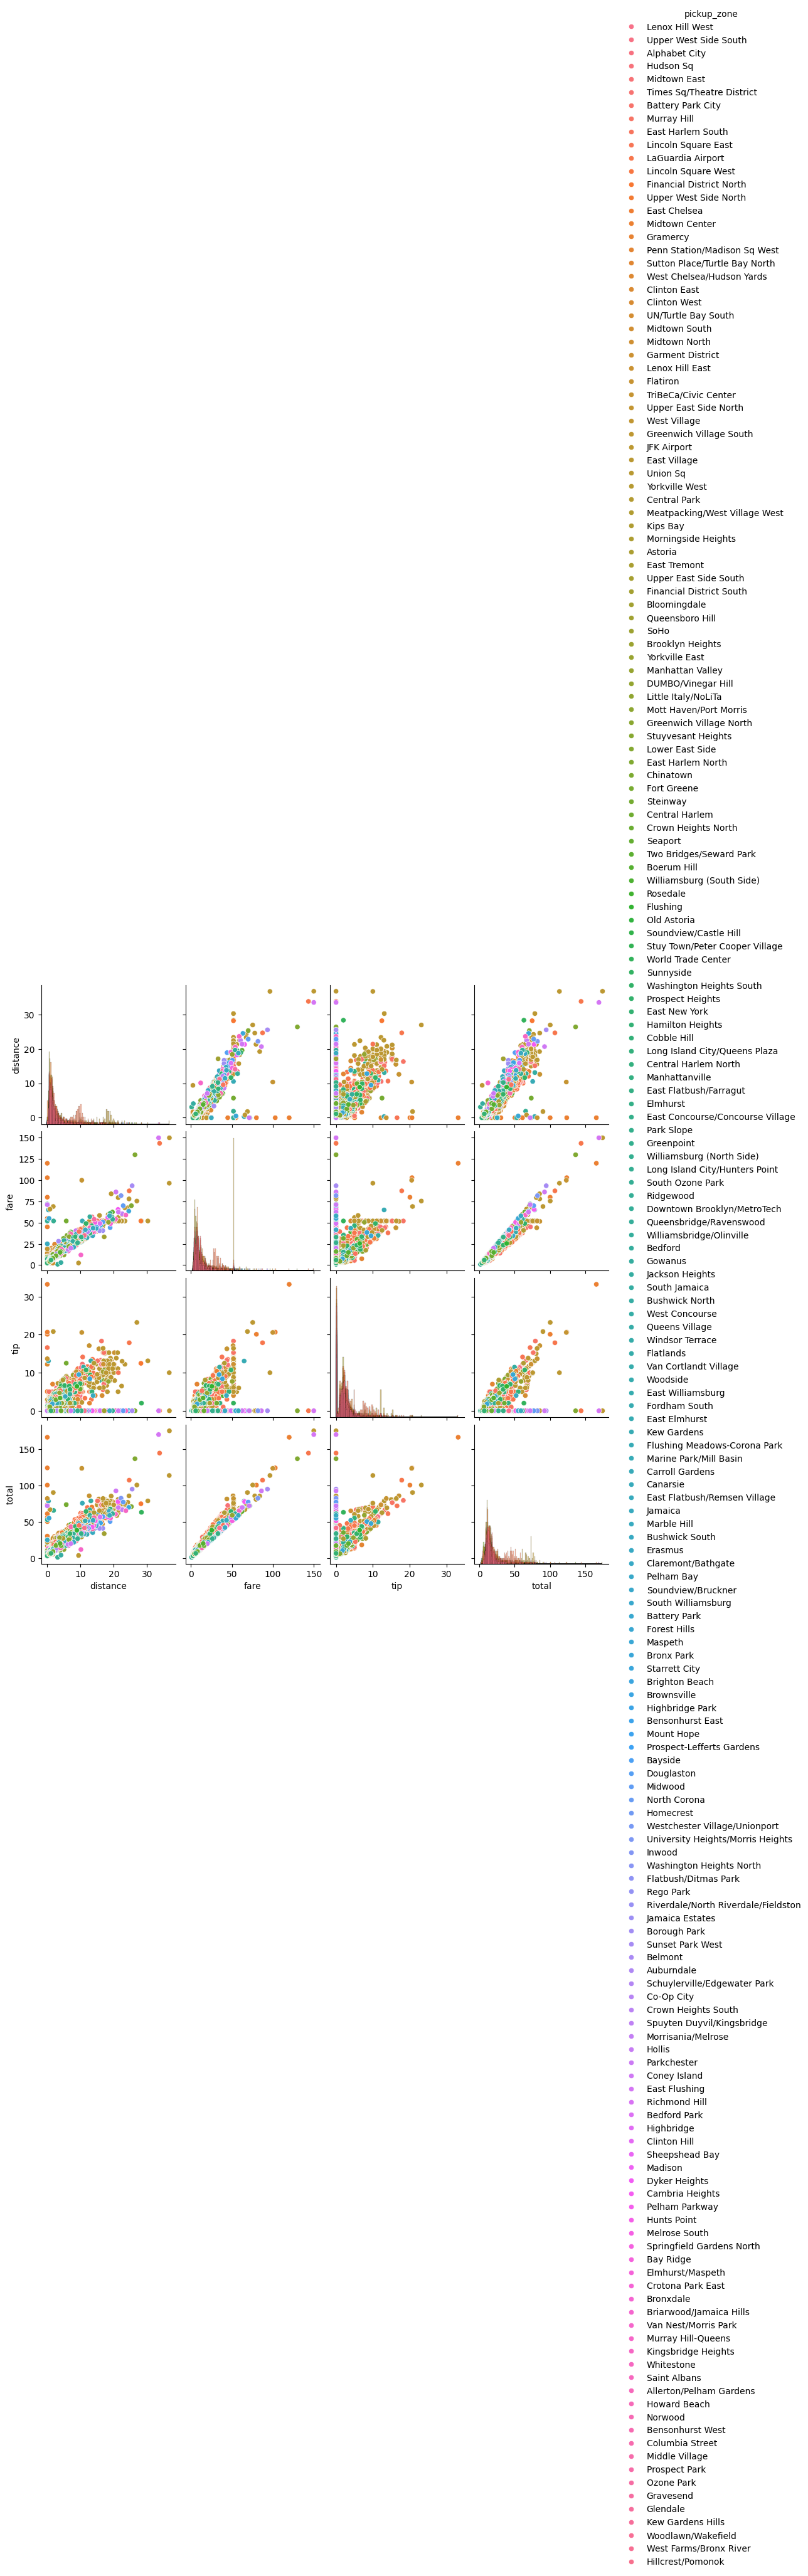

In [21]:

pairplot_data = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()

sns.pairplot(
    pairplot_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)

plt.show()


###**Violin Plot**

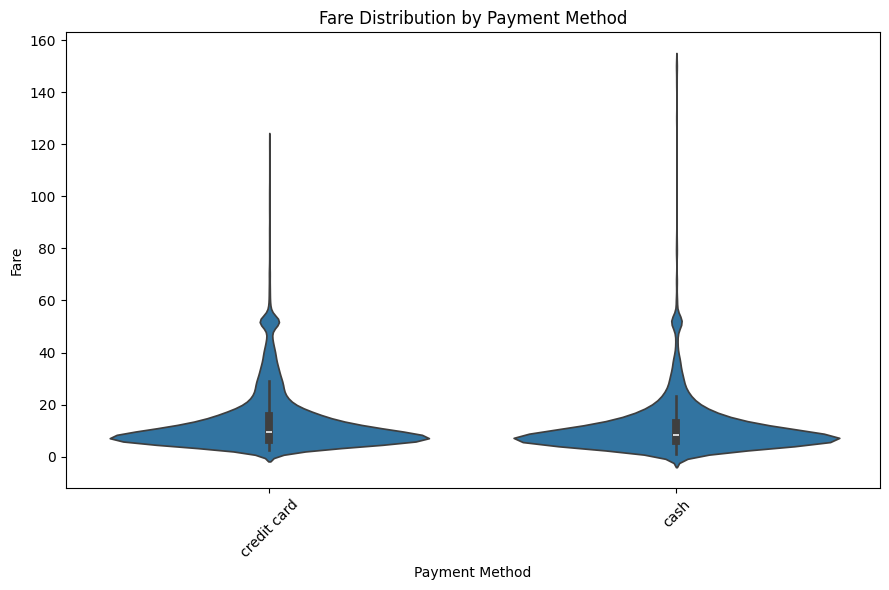

In [22]:

plt.figure(figsize=(9, 6))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
